In [22]:
import os
from pathlib import Path
import cv2
import pandas as pd
import matplotlib.pyplot as plt

In [23]:
DATASET_PATH = Path("../datasets")

for item in DATASET_PATH.iterdir():
    print(item)

..\datasets\Celeb-DF-v2


In [24]:
from pathlib import Path

DATASET_PATH = Path(
    r"C:\Users\Raja Kumar\OneDrive\Desktop\DEEP FAKE DETECTION\datasets\Celeb-DF-v2"
)

print("Dataset exists:", DATASET_PATH.exists())
print("Dataset path:", DATASET_PATH)

Dataset exists: True
Dataset path: C:\Users\Raja Kumar\OneDrive\Desktop\DEEP FAKE DETECTION\datasets\Celeb-DF-v2


In [25]:
print("Celeb-real:", (DATASET_PATH / "Celeb-real").exists())
print("Celeb-synthesis:", (DATASET_PATH / "Celeb-synthesis").exists())
print("YouTube-real:", (DATASET_PATH / "YouTube-real").exists())

Celeb-real: True
Celeb-synthesis: True
YouTube-real: True


In [26]:
real_videos = list((DATASET_PATH / "Celeb-real").rglob("*.mp4"))
fake_videos = list((DATASET_PATH / "Celeb-synthesis").rglob("*.mp4"))
youtube_real = list((DATASET_PATH / "YouTube-real").rglob("*.mp4"))

print("Celeb Real:", len(real_videos))
print("Celeb Fake:", len(fake_videos))
print("YouTube Real:", len(youtube_real))

Celeb Real: 590
Celeb Fake: 5639
YouTube Real: 300


In [27]:
total_videos = len(real_videos) + len(fake_videos) + len(youtube_real)

print("Total videos:", total_videos)

Total videos: 6529


In [31]:
#dataset label 

data = []
for video in real_videos:
    data.append({
        "video_path": str(video),
        "label": 0,
        "class": "Real"
    })

for video in fake_videos:
        data.append({
            "video_path": str(video),
            "label": 1,
            "class": "FAKE"
   })

df = pd.DataFrame(data)
df.head()

,video_path,label,class
0,C:\Users\Raja Kumar\OneDrive\Desktop\DEEP FAKE...,0,Real
1,C:\Users\Raja Kumar\OneDrive\Desktop\DEEP FAKE...,0,Real
2,C:\Users\Raja Kumar\OneDrive\Desktop\DEEP FAKE...,0,Real
3,C:\Users\Raja Kumar\OneDrive\Desktop\DEEP FAKE...,0,Real
4,C:\Users\Raja Kumar\OneDrive\Desktop\DEEP FAKE...,0,Real


In [32]:
df["class"].value_counts()

class
FAKE    5639
Real     590
Name: count, dtype: int64

In [33]:
df["label"].value_counts()

label
1    5639
0     590
Name: count, dtype: int64

In [34]:
#reading the video

video_path = df.iloc[0]["video_path"]

cap = cv2.VideoCapture(video_path)
ret, frame = cap.read()

print("Frame successfully read:", ret)
print("Frame shape:", frame.shape)

cap.release()

Frame successfully read: True
Frame shape: (500, 942, 3)


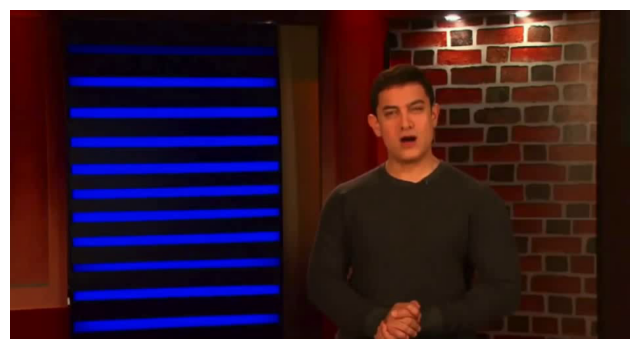

In [41]:
# Frame display 

frame_rgb = cv2.cvtColor(frame,cv2.COLOR_BGR2RGB)

plt.figure(figsize=(8,5))
plt.imshow(frame_rgb)
plt.axis("off")
plt.show()

In [42]:
#video properties

cap = cv2.VideoCapture(video_path)

fps =cap.get(cv2.CAP_PROP_FPS)
frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

duration = frame_count / fps

cap.release()

print("FPS:", fps)
print("Frames:", frame_count)
print("width:", width)
print("Height:", height)
print("Duration:", duration)

FPS: 30.0
Frames: 469
width: 942
Height: 500
Duration: 15.633333333333333


In [ ]:
# multiple video ka eda

def get_video_info(video_path):
    cap = cv2.VideoCapture(str(video_path))

    fps = cap.get(cv2.CAP_PROP_FPS)
    frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

    cap.release()

    duration = frames / fps if fps > 0 else 0

    return fps, frames, width, height, duration

In [45]:
sample_videos = df.sample(20, random_state= 42)

video_info =[]

for _, row in sample_videos.iterrows():

    fps,frames,width,height,duration = get_video_info(
        row["video_path"]
    )

    video_info.append({
        "class": row["class"],
        "fps": fps,
        "frames": frames,
        "width": width,
        "height": height,
        "duration": duration
    })

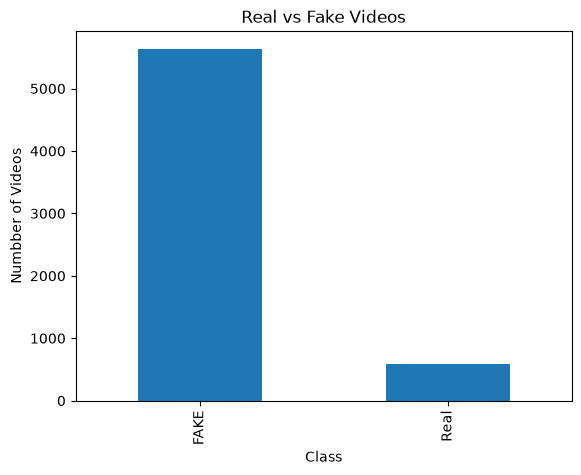

In [46]:
# real vs fake 

df["class"].value_counts().plot(kind="bar")

plt.title("Real vs Fake Videos")
plt.xlabel("Class")
plt.ylabel("Numbber of Videos")

plt.show()

In [48]:
#check imbalance dataset 

counts = df["class"].value_counts()

percentage = counts / counts.sum() * 100
print(percentage)

class
FAKE    90.528175
Real     9.471825
Name: count, dtype: float64


In [51]:
from sklearn.model_selection import train_test_split

# 1️⃣ Train = 70%, temporary = 30%
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["label"],
    random_state=42
)

# 2️⃣ Temporary 30% ko:
#    Validation = 15%
#    Test = 15%

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=42
)

print("Total videos:", len(df))
print("Train videos:", len(train_df))
print("Validation videos:", len(val_df))
print("Test videos:", len(test_df))

Total videos: 6229
Train videos: 4360
Validation videos: 934
Test videos: 935


In [53]:
print("TRAIN")
print(train_df["class"].value_counts())

print("\nVALIDATION")
print(val_df["class"].value_counts())

print("\nTEST")
print(test_df["class"].value_counts())

TRAIN
class
FAKE    3947
Real     413
Name: count, dtype: int64

VALIDATION
class
FAKE    846
Real     88
Name: count, dtype: int64

TEST
class
FAKE    846
Real     89
Name: count, dtype: int64


In [54]:
print(
    train_df["label"].value_counts(normalize=True) * 100
)

print(
    val_df["label"].value_counts(normalize=True) * 100
)

print(
    test_df["label"].value_counts(normalize=True) * 100
)

label
1    90.527523
0     9.472477
Name: proportion, dtype: float64
label
1    90.578158
0     9.421842
Name: proportion, dtype: float64
label
1    90.481283
0     9.518717
Name: proportion, dtype: float64


In [55]:
train_videos = set(train_df["video_path"])
val_videos = set(val_df["video_path"])
test_videos = set(test_df["video_path"])

print("Train ∩ Validation:",
      len(train_videos & val_videos))

print("Train ∩ Test:",
      len(train_videos & test_videos))

print("Validation ∩ Test:",
      len(val_videos & test_videos))

Train ∩ Validation: 0
Train ∩ Test: 0
Validation ∩ Test: 0


In [3]:
!python -m pip install mediapipe

   ---------------------------------------- 0.0/20.1 MB ? eta -:--:--
    --------------------------------------- 0.3/20.1 MB ? eta -:--:--
   -- ------------------------------------- 1.0/20.1 MB 3.9 MB/s eta 0:00:05
   ---- ----------------------------------- 2.4/20.1 MB 5.0 MB/s eta 0:00:04
   ------- -------------------------------- 3.7/20.1 MB 5.5 MB/s eta 0:00:04
   --------- ------------------------------ 5.0/20.1 MB 5.6 MB/s eta 0:00:03
   ------------ --------------------------- 6.3/20.1 MB 5.8 MB/s eta 0:00:03
   --------------- ------------------------ 7.9/20.1 MB 5.9 MB/s eta 0:00:03
   ------------------ --------------------- 9.4/20.1 MB 6.1 MB/s eta 0:00:02
   -------------------- ------------------- 10.5/20.1 MB 6.0 MB/s eta 0:00:02
   ----------------------- ---------------- 12.1/20.1 MB 6.1 MB/s eta 0:00:02
   --------------------------- ------------ 13.6/20.1 MB 6.2 MB/s eta 0:00:02
   ----------------------------- ---------- 14.7/20.1 MB 6.1 MB/s eta 0:00:01
   ------

ERROR: Could not install packages due to an OSError: [WinError 5] Access is denied: 'c:\\Users\\Raja Kumar\\anaconda3\\envs\\fastapi_env\\Lib\\site-packages\\cv2\\cv2.pyd'
Consider using the `--user` option or check the permissions.



In [5]:
%pip install --user mediapipe

  Using cached mediapipe-1.0.1-py3-none-win_amd64.whl.metadata (10 kB)
  Using cached absl_py-2.5.0-py3-none-any.whl.metadata (3.3 kB)
  Using cached sounddevice-0.5.6-py3-none-win_amd64.whl.metadata (1.4 kB)
  Using cached opencv_contrib_python-5.0.0.93-cp37-abi3-win_amd64.whl.metadata (20 kB)
Using cached mediapipe-1.0.1-py3-none-win_amd64.whl (20.1 MB)
Using cached absl_py-2.5.0-py3-none-any.whl (137 kB)
Using cached sounddevice-0.5.6-py3-none-win_amd64.whl (1.0 MB)
Using cached opencv_contrib_python-5.0.0.93-cp37-abi3-win_amd64.whl (53.8 MB)

   ---------------------------------------- 0/4 [opencv-contrib-python]
   ---------------------------------------- 0/4 [opencv-contrib-python]
   ---------------------------------------- 0/4 [opencv-contrib-python]
   ---------- ----------------------------- 1/4 [absl-py]
   ------------------------------ --------- 3/4 [mediapipe]
   ------------------------------ --------- 3/4 [mediapipe]
   ------------------------------ --------- 3/4 [medi

In [1]:
import mediapipe as mp 
print(mp.__version__)

1.0.1
